# CDACL-002 · Customer Segmentation (Shopping Trends)

**Tasks:** (1) categories for discounts · (2) card spending by age, season and location · (3) customer clustering, dominant factors and targeted campaigns.

**Data:** MySQL database `customer segmentation`, table `shopping_trends_dataset` (3,900 rows, 18 columns).

## 1. Connect to MySQL and load the data

In [2]:
!pip install -q pymysql sqlalchemy

import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

from getpass import getpass
# Credentials are entered at run time so they are never saved in the notebook
DB_HOST  = input("MySQL host: ")
DB_PORT  = 3306
DB_USER  = input("MySQL user: ")
DB_PASS  = getpass("MySQL password: ")
DB_NAMES = ["customer segmentation", "customer_segmentation"]
TABLE    = "shopping_trends_dataset"

url = URL.create("mysql+pymysql", username=DB_USER, password=DB_PASS, host=DB_HOST, port=DB_PORT)
engine = create_engine(url, connect_args={"connect_timeout": 15})

df_raw, DB_NAME = None, None
try:
    with engine.connect() as conn:
        dbs = [r[0] for r in conn.execute(text("SHOW DATABASES"))]
        print("Connected ✔  Databases visible:", dbs)
        DB_NAME = next((d for d in DB_NAMES if d in dbs), None) \
                  or next((d for d in dbs if "segment" in d.lower()), None)
        if DB_NAME is None:
            raise RuntimeError("Database not found – check the list above.")
        tables = [r[0] for r in conn.execute(text(f"SHOW TABLES FROM `{DB_NAME}`"))]
        print(f"Tables in `{DB_NAME}`:", tables)
        tbl = TABLE if TABLE in tables else tables[0]
        df_raw = pd.read_sql(text(f"SELECT * FROM `{DB_NAME}`.`{tbl}`"), conn)
        print(f"Loaded `{DB_NAME}`.`{tbl}` → {df_raw.shape}")
except Exception as e:
    print("❌ Could not load from MySQL:\n  ", type(e).__name__, str(e)[:300])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 685.7 kB/s eta 0:00:00
Connected ✔  Databases visible: ['information_schema', 'Automobile Insurance', 'Fast food analysis', 'OnlineBookstore', 'US_Shoppers', 'customer segmentation', 'datamites_sql', 'dell-company', 'mysql', 'onlinebookstore', 'performance_schema', 'project_automobile_insurance', 'project_banking', 'project_crop_production_india', 'project_csat_analytics', 'project_customer_segmentation', 'project_food', 'project_health_data', 'project_hr_analytics', 'project_itsm', 'project_job_market_analysis', 'project_medical_data_history', 'project_movie_database', 'project_orders', 'project_profit_analysis', 'project_purchase_pattern_analysis', 'project_sales', 'project_service_data', 'project_shopping Data', 'project_shopping_trends', 'project_snack_analysis', 'project_supply_chain_data', 'project_telecom', 'sys', 'test']
Tables in `customer segmentation`: ['Subscribed_customers', 'customer segmentation', 'shopping_trends'

## 2. Imports and settings

In [3]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

## 3. Clean and standardise the columns

In [5]:
def norm(c):
    return re.sub(r"[^a-z0-9]+", "_", str(c).strip().lower()).strip("_")
def squash(c):
    return norm(c).replace("_", "")          # 'purchase_amount_usd' -> 'purchaseamountusd'

df = df_raw.copy()
df.columns = [norm(c) for c in df.columns]

aliases = {
    "customer_id": ["customer_id", "customerid", "id"],
    "age": ["age"], "gender": ["gender"],
    "item": ["item_purchased", "item"], "category": ["category"],
    "amount": ["purchase_amount_usd", "purchase_amount", "amount"],
    "location": ["location", "state"], "size": ["size"], "color": ["color", "colour"],
    "season": ["season"], "rating": ["review_rating", "rating"],
    "subscription": ["subscription_status", "subscription"],
    "shipping": ["shipping_type", "shipping"],
    "discount": ["discount_applied", "discount"],
    "promo": ["promo_code_used", "promo_code", "promo"],
    "prev_purchases": ["previous_purchases"],
    "payment": ["payment_method", "preferred_payment_method"],
    "frequency": ["frequency_of_purchases", "frequency"],
}
squashed = {squash(c): c for c in df.columns}          # lookup ignoring underscores
rename, used = {}, set()
for std, opts in aliases.items():
    for o in opts:
        src = squashed.get(squash(o))
        if src and src not in used:
            rename[src] = std; used.add(src)
            break
df = df.rename(columns=rename)
df = df.loc[:, ~df.columns.duplicated()]

missing = [k for k in aliases if k not in df.columns]
print("Standardised columns:", list(df.columns))
print("Missing:", missing or "none")

for c in ["age", "amount", "rating", "prev_purchases"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
for c in ["subscription", "discount", "promo"]:
    df[c] = df[c].astype(str).str.strip().str.title()
for c in df.select_dtypes("object"):
    df[c] = df[c].astype(str).str.strip()

print("\nNulls:\n", df.isna().sum()[df.isna().sum() > 0].to_string() or "none")
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().dropna(subset=["age", "amount", "category"])
print("Final shape:", df.shape)
df.head()

Standardised columns: ['customer_id', 'age', 'gender', 'item', 'category', 'amount', 'location', 'size', 'color', 'season', 'rating', 'subscription', 'shipping', 'discount', 'promo', 'prev_purchases', 'payment', 'frequency']
Missing: none

Nulls:
 Series([], )
Duplicate rows: 0
Final shape: (3900, 18)


,customer_id,age,gender,item,category,amount,location,size,color,season,rating,subscription,shipping,discount,promo,prev_purchases,payment,frequency
0,1,56,Male,Bag,Accessories,374.86,New York,L,Red,Fall,3,No,Standard,Yes,No,7,PayPal,Fortnightly
1,2,46,Male,Shoes,Home Decor,33.28,Los Angeles,S,Black,Spring,2,No,Express,Yes,No,3,UPI,Weekly
2,3,32,Female,Laptop,Home Decor,117.45,Houston,S,Black,Fall,4,No,Standard,Yes,Yes,13,UPI,Monthly
3,4,60,Male,Bag,Home Decor,356.05,Chicago,M,Green,Summer,2,Yes,Express,No,No,14,PayPal,Weekly
4,5,25,Female,Laptop,Accessories,393.50,Houston,M,Black,Winter,2,Yes,Express,No,No,5,Cash,Fortnightly


### Values in each text column

In [6]:
for c in ["category", "item", "payment", "frequency", "season", "shipping", "location", "size"]:
    print(f"\n{c} ({df[c].nunique()} unique):")
    print(df[c].value_counts().to_dict())
print("\nAmount range:", df.amount.min(), "-", df.amount.max(), "| Rating range:", df.rating.min(), "-", df.rating.max())


category (5 unique):
{'Accessories': 820, 'Clothing': 796, 'Electronics': 772, 'Home Decor': 760, 'Sports': 752}

item (8 unique):
{'Shoes': 552, 'Watch': 502, 'Football': 488, 'T-Shirt': 479, 'Curtains': 479, 'Bag': 474, 'Laptop': 466, 'Phone': 460}

payment (5 unique):
{'Credit Card': 802, 'UPI': 792, 'PayPal': 791, 'Debit Card': 772, 'Cash': 743}

frequency (3 unique):
{'Monthly': 1319, 'Weekly': 1308, 'Fortnightly': 1273}

season (4 unique):
{'Spring': 1047, 'Fall': 987, 'Winter': 961, 'Summer': 905}

shipping (2 unique):
{'Express': 1973, 'Standard': 1927}

location (5 unique):
{'New York': 812, 'Los Angeles': 806, 'Chicago': 777, 'Houston': 764, 'Miami': 741}

size (4 unique):
{'XL': 1013, 'S': 980, 'M': 957, 'L': 950}

Amount range: 10.08 - 499.84 | Rating range: 1 - 5


## 4. Task 1 – Which categories should get discounts?
Category metrics, discount response (avg order with ÷ without discount) and a rank-based discount priority score.

,orders,revenue,avg_amount,avg_rating,discount_rate,promo_rate,subscriber_rate,revenue_share,avg_with_disc,avg_without_disc,disc_spend_ratio
category,,,,,,,,,,,
Clothing,796,208775.03,262.280,3.038,0.475,0.466,0.485,0.210,270.976,254.416,1.065
Accessories,820,208063.00,253.735,3.010,0.507,0.496,0.499,0.209,252.045,255.476,0.987
Home Decor,760,196999.83,259.210,2.983,0.499,0.470,0.528,0.198,253.103,265.285,0.954
Electronics,772,193682.52,250.884,3.060,0.469,0.483,0.496,0.194,249.129,252.434,0.987
Sports,752,188858.42,251.142,3.077,0.481,0.513,0.468,0.190,250.164,252.049,0.993


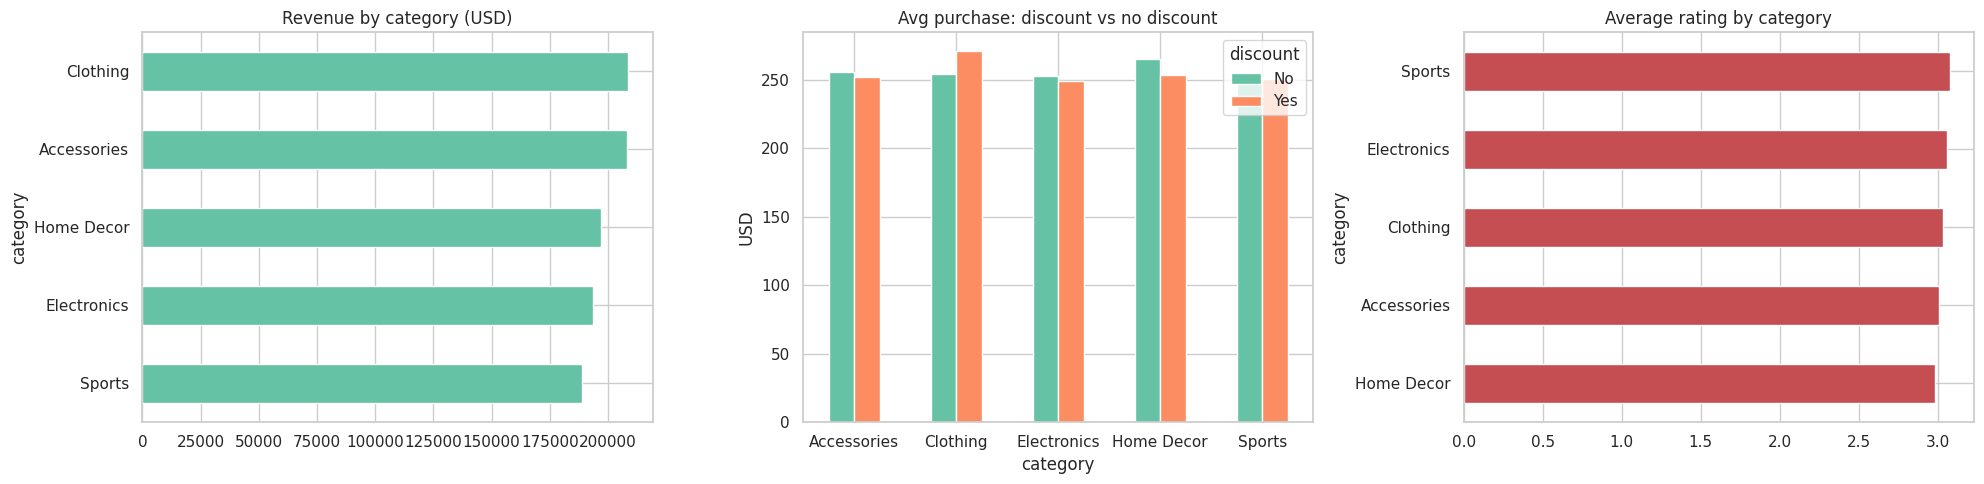

,low_revenue,low_rating,low_loyalty,disc_responsive,priority_score
category,,,,,
Sports,0.8,0.0,0.8,0.8,0.60
Clothing,0.0,0.4,0.6,1.0,0.50
Electronics,0.6,0.2,0.4,0.6,0.45
Home Decor,0.4,0.8,0.0,0.2,0.35
Accessories,0.2,0.6,0.2,0.4,0.35


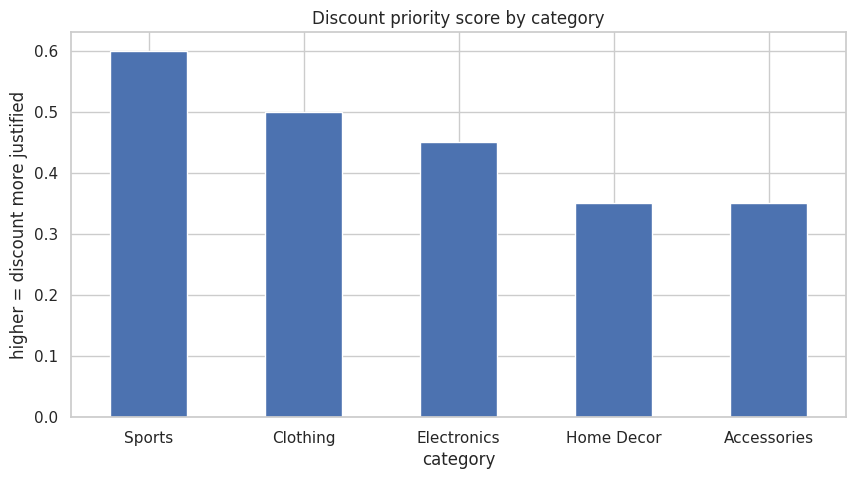

➡ Recommended categories for discounts: ['Sports', 'Clothing']

• Sports: 19.0% of revenue, 752 orders, avg rating 3.08, subscribers 47%, current discount use 48%, avg spend with discount $250.16 vs $252.05 without

• Clothing: 21.0% of revenue, 796 orders, avg rating 3.04, subscribers 48%, current discount use 47%, avg spend with discount $270.98 vs $254.42 without

Lowest-selling items in those categories (best discount candidates):


,category,item,orders,revenue,avg_amount,avg_rating,discount_rate
10,Clothing,Football,89,24425.40,274.44,3.18,0.45
12,Clothing,Phone,91,21413.15,235.31,2.87,0.45
9,Clothing,Curtains,92,23972.74,260.57,3.07,0.45
39,Sports,Watch,78,19235.88,246.61,2.90,0.45
33,Sports,Curtains,81,18649.20,230.24,3.19,0.49
38,Sports,T-Shirt,88,22115.23,251.31,3.18,0.48


In [15]:
df["disc_flag"]  = (df["discount"] == "Yes").astype(int)
df["promo_flag"] = (df["promo"] == "Yes").astype(int)
df["sub_flag"]   = (df["subscription"] == "Yes").astype(int)

# --- category metrics ---
cat = df.groupby("category").agg(
    orders=("amount", "size"), revenue=("amount", "sum"), avg_amount=("amount", "mean"),
    avg_rating=("rating", "mean"), discount_rate=("disc_flag", "mean"),
    promo_rate=("promo_flag", "mean"), subscriber_rate=("sub_flag", "mean"))
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
by_disc = df.pivot_table(index="category", columns="discount", values="amount", aggfunc="mean")
cat["avg_with_disc"] = by_disc["Yes"]
cat["avg_without_disc"] = by_disc["No"]
cat["disc_spend_ratio"] = cat["avg_with_disc"] / cat["avg_without_disc"]
display(cat.sort_values("revenue", ascending=False).round(3))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
cat["revenue"].sort_values().plot.barh(ax=ax[0], title="Revenue by category (USD)")
by_disc.plot.bar(ax=ax[1], rot=0, title="Avg purchase: discount vs no discount").set_ylabel("USD")
cat["avg_rating"].sort_values().plot.barh(ax=ax[2], color="#C44E52", title="Average rating by category")
plt.tight_layout(); plt.show()

# --- item level ---
item_tbl = (df.groupby(["category", "item"])
              .agg(orders=("amount", "size"), revenue=("amount", "sum"), avg_amount=("amount", "mean"),
                   avg_rating=("rating", "mean"), discount_rate=("disc_flag", "mean"))
              .reset_index().sort_values(["category", "orders"]))

# --- discount priority score (higher = discount more justified) ---
score = pd.DataFrame(index=cat.index)
score["low_revenue"]     = 1 - cat["revenue_share"].rank(pct=True)
score["low_rating"]      = 1 - cat["avg_rating"].rank(pct=True)
score["low_loyalty"]     = 1 - cat["subscriber_rate"].rank(pct=True)
score["disc_responsive"] = cat["disc_spend_ratio"].rank(pct=True)
score["priority_score"]  = score.mean(axis=1)
score = score.sort_values("priority_score", ascending=False)
display(score.round(2))

score["priority_score"].plot.bar(rot=0, color="#4C72B0", title="Discount priority score by category")
plt.ylabel("higher = discount more justified"); plt.show()

top = score.index[:2].tolist()
print("➡ Recommended categories for discounts:", top)
for c in top:
    r = cat.loc[c]
    print(f"\n• {c}: {r.revenue_share:.1%} of revenue, {int(r.orders)} orders, avg rating {r.avg_rating:.2f}, "
          f"subscribers {r.subscriber_rate:.0%}, current discount use {r.discount_rate:.0%}, "
          f"avg spend with discount ${r.avg_with_disc:.2f} vs ${r.avg_without_disc:.2f} without")
print("\nLowest-selling items in those categories (best discount candidates):")
display(item_tbl[item_tbl.category.isin(top)].groupby("category").head(3).round(2))

**Finding:** discount **Sports** (lowest revenue and loyalty, highest rating); use bundle discounts on **Clothing** (+6.5% basket); **don't discount Home Decor** (basket shrinks 5%, lowest rating).

## 5. Task 2 – Card spending by age, season and location

Card transactions: 1574 of 3900 (40.4%), card spend $405,807 of $996,379


transactions            total_spend              avg_spend  \
payment    Credit Card Debit Card Credit Card Debit Card Credit Card   
age_group                                                              
18-25              145        124    37197.95   33169.31      256.54   
26-35              161        160    41640.74   40180.72      258.64   
36-45              170        177    45719.81   42802.86      268.94   
46-55              181        147    44987.99   39892.57      248.55   
56-65              145        164    40124.87   40090.13      276.72   
66+                  0          0        0.00       0.00         NaN   

                      
payment   Debit Card  
age_group             
18-25         267.49  
26-35         251.13  
36-45         241.82  
46-55         271.38  
56-65         244.45  
66+              NaN

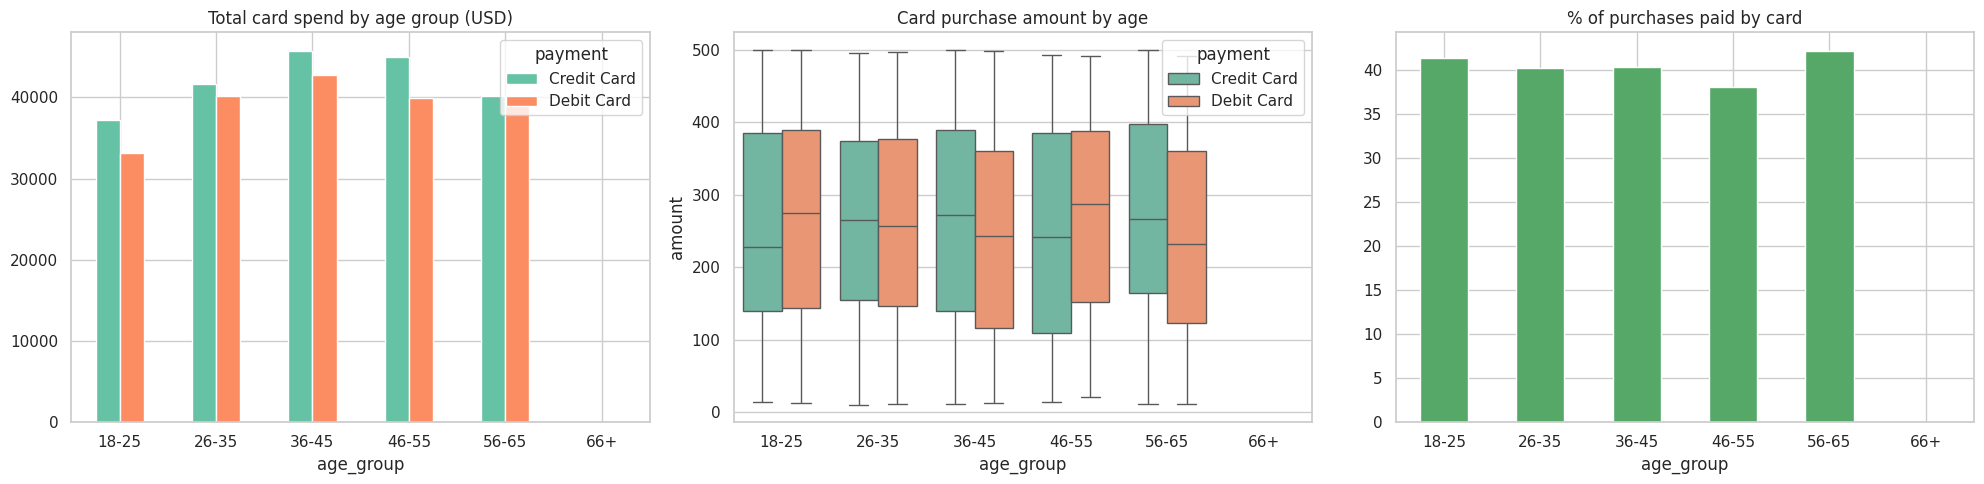

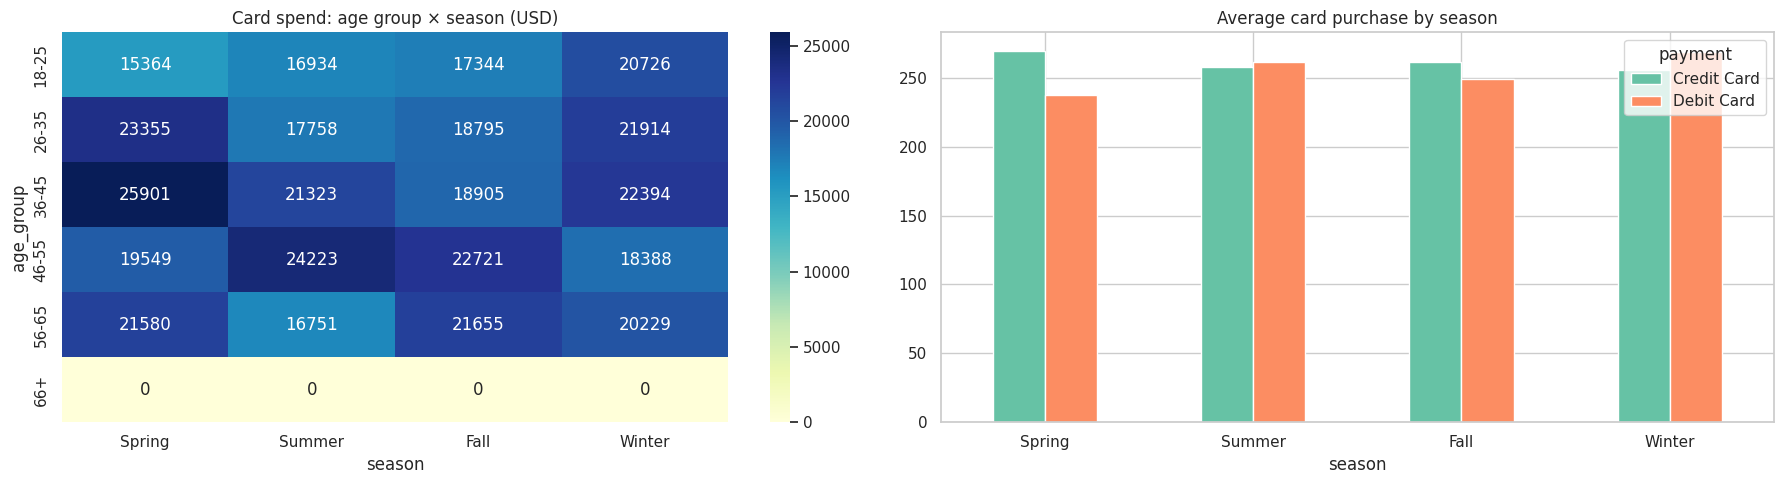

,transactions,total,avg,share_of_card_spend
season,,,,
Spring,416,105748.28,254.203,0.261
Summer,374,96988.84,259.328,0.239
Fall,389,99418.85,255.575,0.245
Winter,395,103650.98,262.408,0.255


,transactions,total_spend,avg_spend,card_share_of_location
location,,,,
New York,347,90702.56,261.39,0.43
Los Angeles,331,83297.97,251.66,0.41
Chicago,315,81730.80,259.46,0.41
Houston,301,78587.57,261.09,0.39
Miami,280,71488.05,255.31,0.38


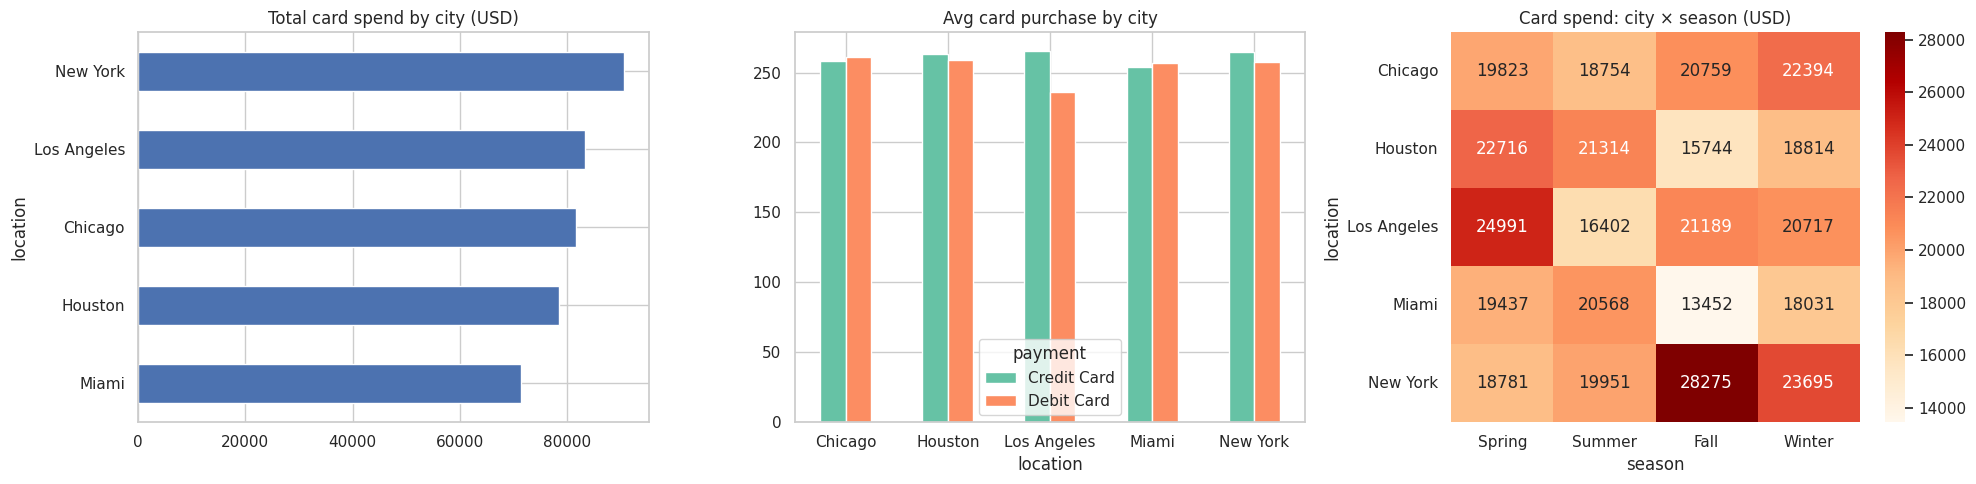

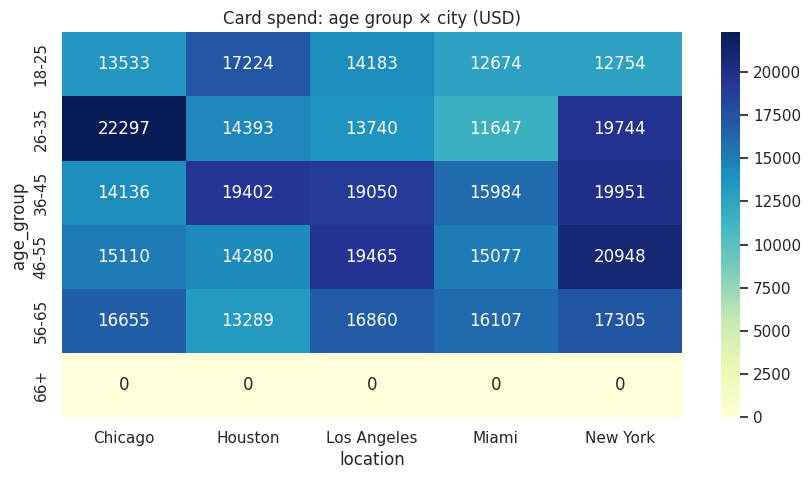

,ANOVA p,Kruskal p,significant (p<0.05)
age_group,0.9717,0.9748,False
season,0.8431,0.8279,False
location,0.8881,0.8892,False
card use vs age (chi²),0.5306,NaN,False


In [8]:
from scipy import stats

# --- setup ---
season_order = ["Spring", "Summer", "Fall", "Winter"]
bins   = [17, 25, 35, 45, 55, 65, 100]
labels = ["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
df["age_group"] = pd.cut(df["age"], bins=bins, labels=labels)
df["is_card"] = df["payment"].str.contains("card", case=False)
card = df[df["is_card"]].copy()
print(f"Card transactions: {len(card)} of {len(df)} ({len(card)/len(df):.1%}), "
      f"card spend ${card.amount.sum():,.0f} of ${df.amount.sum():,.0f}")

# --- 1. Card spend by AGE ---
age_card = card.groupby(["age_group", "payment"]).agg(
    transactions=("amount", "size"), total_spend=("amount", "sum"), avg_spend=("amount", "mean")).round(2)
display(age_card.unstack("payment"))

share = df.groupby("age_group")["is_card"].mean()
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
card.pivot_table(index="age_group", columns="payment", values="amount", aggfunc="sum").plot.bar(
    ax=ax[0], rot=0, title="Total card spend by age group (USD)")
sns.boxplot(data=card, x="age_group", y="amount", hue="payment", ax=ax[1]).set_title("Card purchase amount by age")
(share * 100).plot.bar(ax=ax[2], rot=0, color="#55A868", title="% of purchases paid by card")
plt.tight_layout(); plt.show()

# --- 2. Effect of SEASON ---
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
sns.heatmap(card.pivot_table(index="age_group", columns="season", values="amount", aggfunc="sum")[season_order],
            annot=True, fmt=".0f", cmap="YlGnBu", ax=ax[0]).set_title("Card spend: age group × season (USD)")
card.pivot_table(index="season", columns="payment", values="amount", aggfunc="mean").loc[season_order].plot.bar(
    ax=ax[1], rot=0, title="Average card purchase by season")
plt.tight_layout(); plt.show()

season_tbl = card.groupby("season").agg(transactions=("amount", "size"), total=("amount", "sum"),
                                        avg=("amount", "mean")).loc[season_order]
season_tbl["share_of_card_spend"] = season_tbl.total / season_tbl.total.sum()
display(season_tbl.round(3))

# --- 3. Effect of LOCATION ---
loc_tbl = card.groupby("location").agg(transactions=("amount", "size"), total_spend=("amount", "sum"),
                                       avg_spend=("amount", "mean")).sort_values("total_spend", ascending=False)
loc_tbl["card_share_of_location"] = df.groupby("location")["is_card"].mean()
display(loc_tbl.round(2))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
loc_tbl["total_spend"].sort_values().plot.barh(ax=ax[0], color="#4C72B0", title="Total card spend by city (USD)")
card.pivot_table(index="location", columns="payment", values="amount", aggfunc="mean").plot.bar(
    ax=ax[1], rot=0, title="Avg card purchase by city")
sns.heatmap(card.pivot_table(index="location", columns="season", values="amount", aggfunc="sum")[season_order],
            annot=True, fmt=".0f", cmap="OrRd", ax=ax[2]).set_title("Card spend: city × season (USD)")
plt.tight_layout(); plt.show()

sns.heatmap(card.pivot_table(index="age_group", columns="location", values="amount", aggfunc="sum"),
            annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Card spend: age group × city (USD)"); plt.show()

# --- 4. Statistical tests ---
def pvals(col):
    groups = [g["amount"].values for _, g in card.groupby(col, observed=True) if len(g) > 5]
    return stats.f_oneway(*groups).pvalue, stats.kruskal(*groups).pvalue
tests = pd.DataFrame({c: pvals(c) for c in ["age_group", "season", "location"]},
                     index=["ANOVA p", "Kruskal p"]).T
tests.loc["card use vs age (chi²)"] = [stats.chi2_contingency(pd.crosstab(df["age_group"], df["is_card"]))[1], np.nan]
tests["significant (p<0.05)"] = tests["ANOVA p"] < 0.05
display(tests.round(4))

**Finding:** spend per card purchase does not differ by age, season or city (all p > 0.8). Totals differ by volume: 36–45 year olds, Spring and New York lead.

## 6. Task 3 – Clustering 1: K-Means on all behaviour features (K selection)

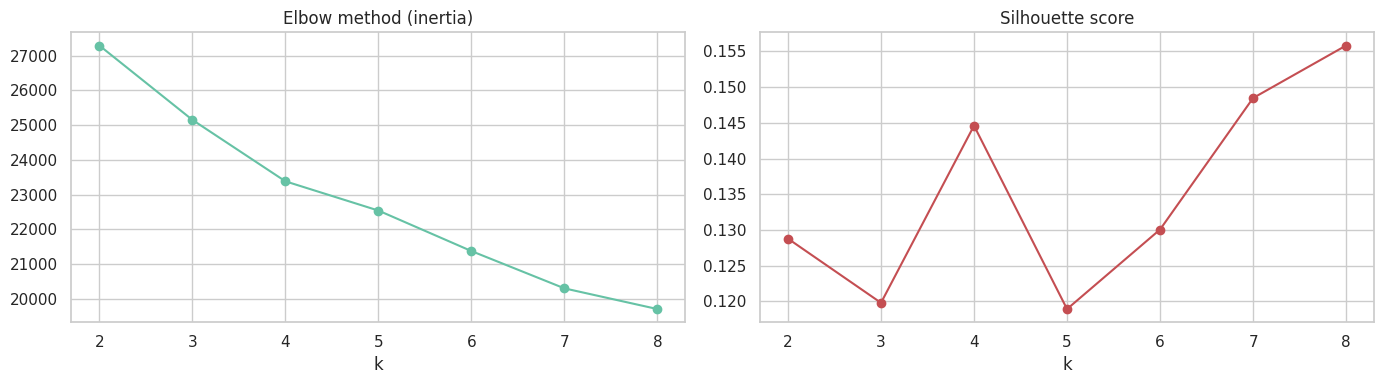

Silhouette by k: {2: np.float64(0.129), 3: np.float64(0.12), 4: np.float64(0.145), 5: np.float64(0.119), 6: np.float64(0.13), 7: np.float64(0.148), 8: np.float64(0.156)}

K = 4  | silhouette = 0.145
cluster
0    1052
1     943
2     951
3     954


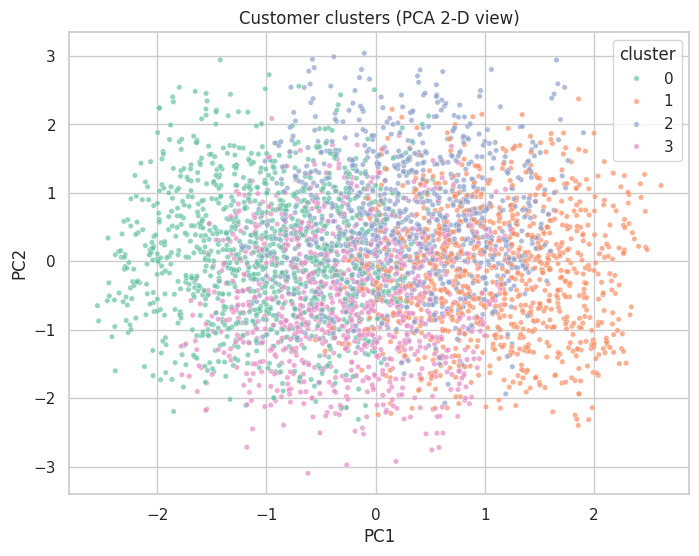

In [9]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# helper columns (safe to re-run)
df["disc_flag"]  = (df["discount"] == "Yes").astype(int)
df["promo_flag"] = (df["promo"] == "Yes").astype(int)
df["sub_flag"]   = (df["subscription"] == "Yes").astype(int)
df["male_flag"]  = (df["gender"].str.lower() == "male").astype(int)
df["express_flag"] = (df["shipping"] == "Express").astype(int)
df["freq_per_year"] = df["frequency"].map({"Weekly": 52, "Fortnightly": 26, "Monthly": 12}).fillna(12)
df["age_group"] = pd.cut(df["age"], bins=[17, 25, 35, 45, 55, 65, 100],
                         labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"])

features = ["age", "amount", "prev_purchases", "freq_per_year", "rating",
            "sub_flag", "disc_flag", "promo_flag"]
X = df[features].fillna(df[features].median())
Xs = StandardScaler().fit_transform(X)

ks, inertia, sil = list(range(2, 9)), [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xs)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(Xs, m.labels_, sample_size=2000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow method (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-", color="#C44E52"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
print("Silhouette by k:", {k: round(s, 3) for k, s in zip(ks, sil)})

K = 4          # <-- change to 3, 4 or 5 after looking at the elbow / silhouette charts
km = KMeans(n_clusters=K, n_init=20, random_state=42).fit(Xs)
df["cluster"] = km.labels_
print(f"\nK = {K}  | silhouette = {silhouette_score(Xs, df['cluster'], sample_size=2000, random_state=42):.3f}")
print(df["cluster"].value_counts().sort_index().to_string())

pcs = PCA(2, random_state=42).fit_transform(Xs)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=df["cluster"], palette="Set2", s=15, alpha=.7)
plt.title("Customer clusters (PCA 2-D view)"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

### Cluster profiles

cluster,0,1,2,3
customers,1052,943,951,954
avg_age,41.12,41.16,41.18,41.34
avg_amount,251.53,258.24,260.58,252.02
avg_rating,3.0,3.15,3.03,2.96
avg_prev_purchases,7.03,6.95,6.93,6.83
purchases_per_year,29.82,29.51,30.87,29.75
subscriber_pct,0.5,0.48,0.5,0.5
discount_pct,0.0,1.0,0.0,1.0
promo_pct,0.0,1.0,1.0,0.0
male_pct,0.49,0.51,0.51,0.5


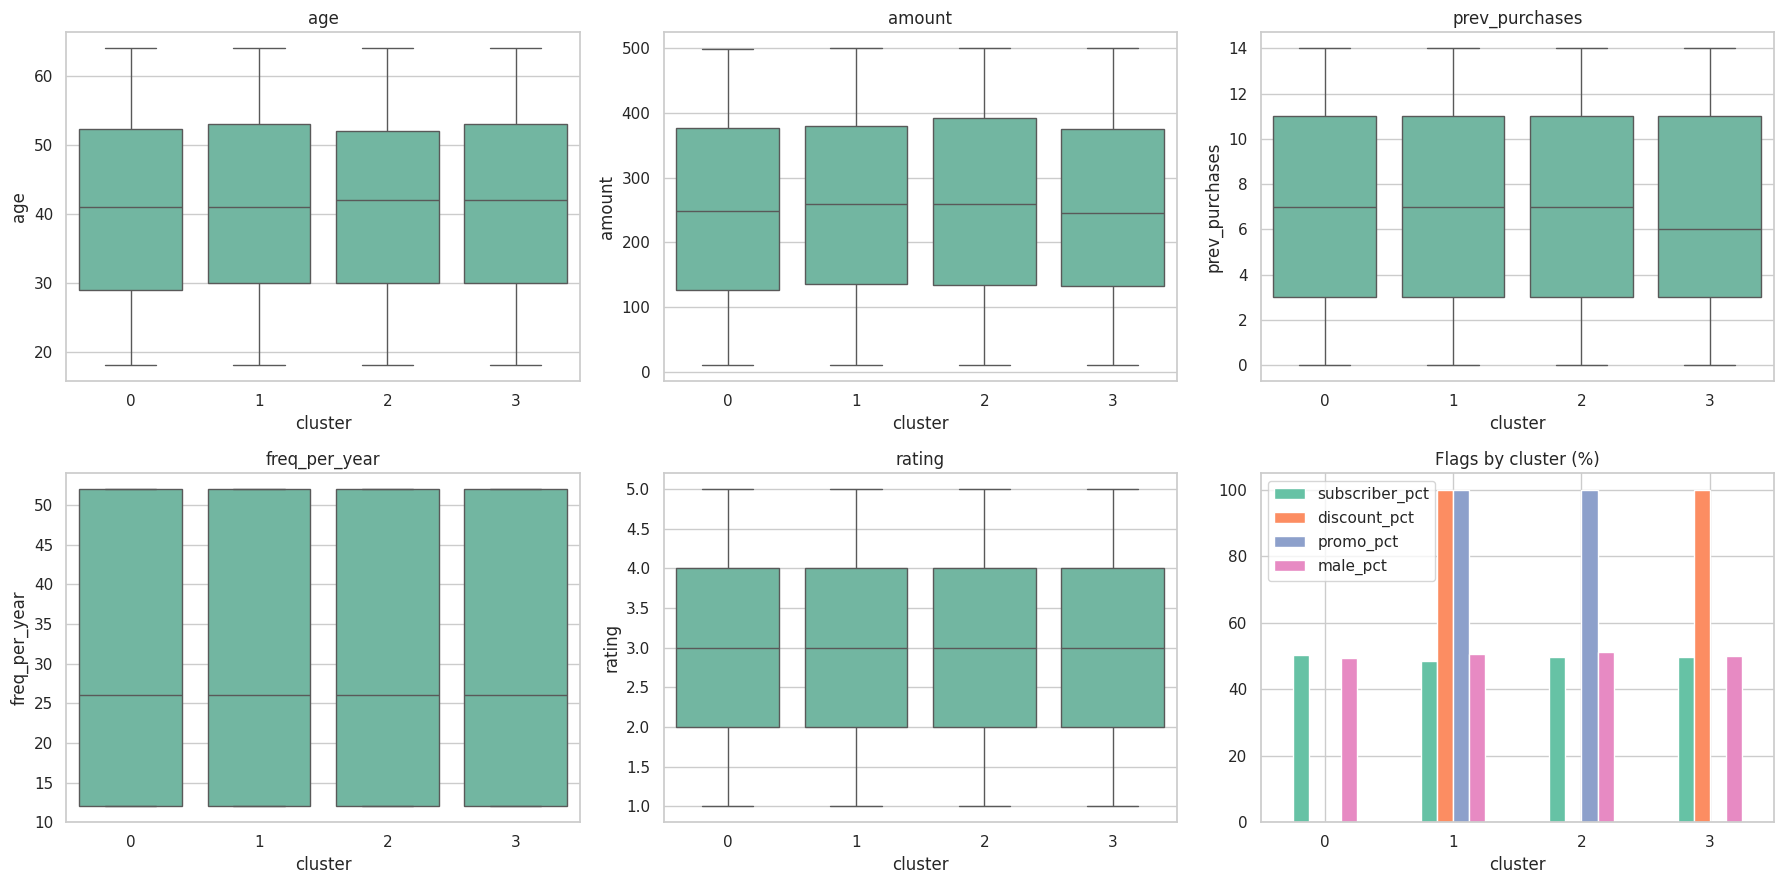

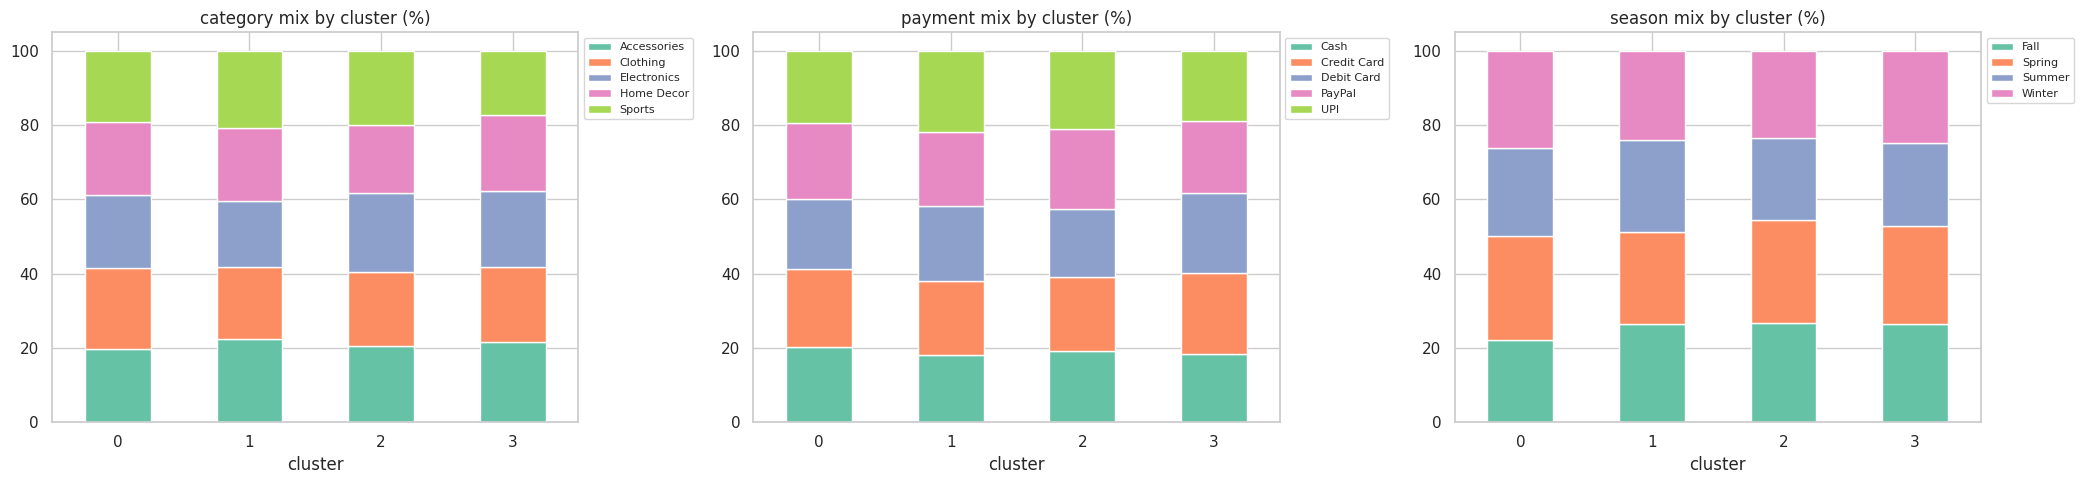

In [10]:
profile = df.groupby("cluster").agg(
    customers=("amount", "size"), avg_age=("age", "mean"), avg_amount=("amount", "mean"),
    avg_rating=("rating", "mean"), avg_prev_purchases=("prev_purchases", "mean"),
    purchases_per_year=("freq_per_year", "mean"), subscriber_pct=("sub_flag", "mean"),
    discount_pct=("disc_flag", "mean"), promo_pct=("promo_flag", "mean"),
    male_pct=("male_flag", "mean"), express_pct=("express_flag", "mean"))
for c in ["category", "item", "season", "payment", "location", "frequency", "age_group"]:
    profile["top_" + c] = df.groupby("cluster")[c].agg(lambda s: s.value_counts().index[0])
profile["revenue_share"] = df.groupby("cluster")["amount"].sum() / df["amount"].sum()
display(profile.round(2).T)

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
for a, col in zip(ax.flat, ["age", "amount", "prev_purchases", "freq_per_year", "rating"]):
    sns.boxplot(data=df, x="cluster", y=col, ax=a).set_title(col)
(profile[["subscriber_pct", "discount_pct", "promo_pct", "male_pct"]] * 100).plot.bar(
    ax=ax[1, 2], rot=0, title="Flags by cluster (%)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
for a, c in zip(ax, ["category", "payment", "season"]):
    (pd.crosstab(df["cluster"], df[c], normalize="index") * 100).plot.bar(
        stacked=True, rot=0, ax=a, title=f"{c} mix by cluster (%)").legend(bbox_to_anchor=(1, 1), fontsize=8)
plt.tight_layout(); plt.show()

### Dominant factors (Random Forest + centroid spread)

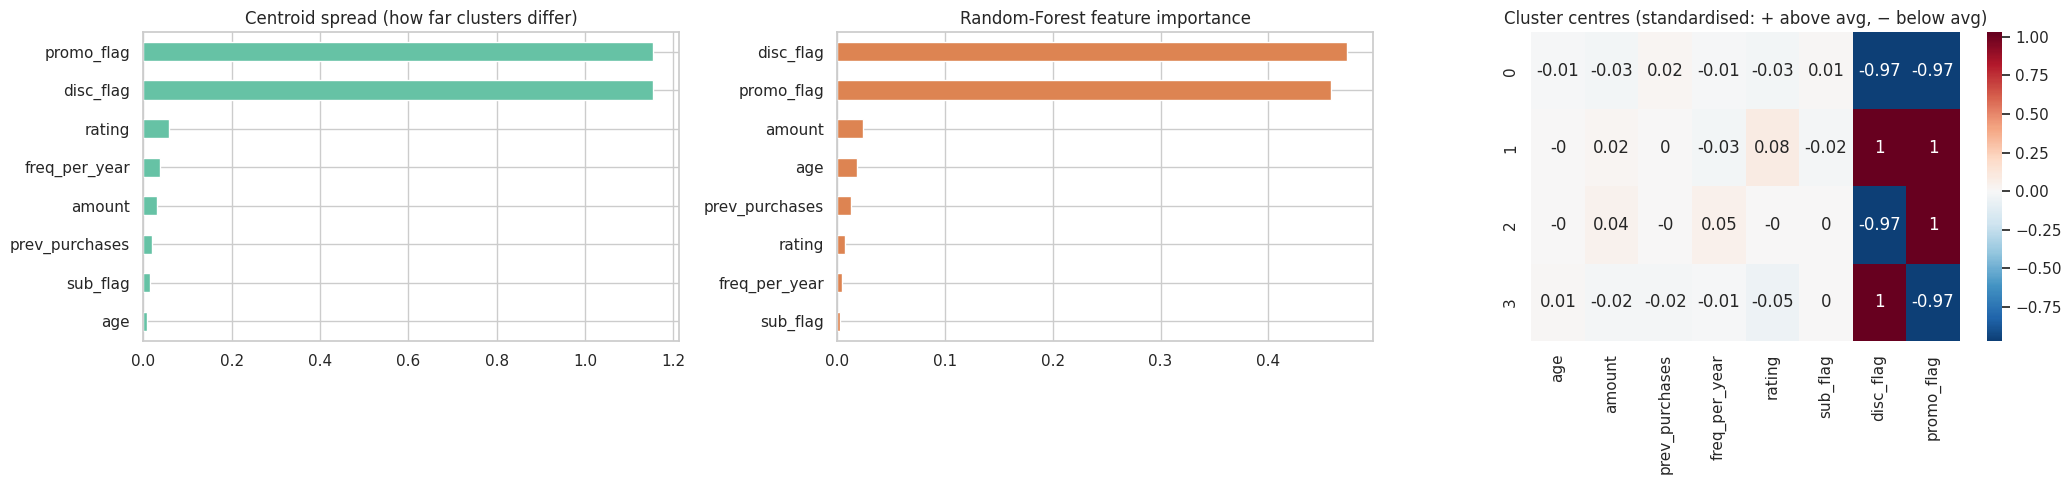

Dominant factors (most → least): ['disc_flag', 'promo_flag', 'amount', 'age', 'prev_purchases', 'rating', 'freq_per_year', 'sub_flag']


In [12]:
from sklearn.ensemble import RandomForestClassifier

centres = pd.DataFrame(km.cluster_centers_, columns=features)
spread = centres.std().sort_values(ascending=False)
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X, df["cluster"])
imp = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)

fig, ax = plt.subplots(1, 3, figsize=(21, 5))
spread.sort_values().plot.barh(ax=ax[0], title="Centroid spread (how far clusters differ)")
imp.sort_values().plot.barh(ax=ax[1], color="#DD8452", title="Random-Forest feature importance")
sns.heatmap(centres.round(2), annot=True, cmap="RdBu_r", center=0, ax=ax[2]).set_title(
    "Cluster centres (standardised: + above avg, − below avg)")
plt.tight_layout(); plt.show()
print("Dominant factors (most → least):", imp.index.tolist())

**Finding:** discount and promo-code use dominate → four offer-response segments: Full-Price Loyalists, Deal Maximisers, Promo-Code Responders, Discount-Only Shoppers.

### Campaigns per offer segment

In [13]:
med = df[["age", "amount", "prev_purchases", "freq_per_year"]].median()
def name_segment(r):
    t = ["Young" if r.avg_age < med.age - 5 else "Senior" if r.avg_age > med.age + 5 else "Middle-aged"]
    if r.purchases_per_year > med.freq_per_year * 1.3: t.append("Frequent")
    elif r.purchases_per_year < med.freq_per_year * 0.8: t.append("Occasional")
    if r.avg_prev_purchases > med.prev_purchases + 3: t.append("Loyal")
    elif r.avg_prev_purchases < med.prev_purchases - 3: t.append("New")
    if r.avg_amount > med.amount * 1.15: t.append("High-spend")
    elif r.avg_amount < med.amount * 0.85: t.append("Budget")
    if r.discount_pct > 0.6: t.append("Deal-seekers")
    elif r.subscriber_pct > 0.6: t.append("Subscribers")
    return " ".join(t)

def campaign(r):
    ideas = []
    if r.discount_pct > 0.5 or r.promo_pct > 0.5:
        ideas.append(f"Time-limited promo codes and bundles on {r.top_category} to grow basket size")
    else:
        ideas.append(f"Full-price new arrivals / premium {r.top_category}; avoid blanket discounts")
    if r.subscriber_pct < 0.4:
        ideas.append("Subscription drive: free express shipping + welcome discount for joining")
    else:
        ideas.append("Loyalty rewards: points, early access, birthday perks for subscribers")
    if r.purchases_per_year < med.freq_per_year:
        ideas.append("Reminder / win-back emails timed to their buying cycle")
    else:
        ideas.append("Personalised recommendations and cross-sell from related categories")
    if r.avg_amount > med.amount:
        ideas.append("Upsell premium lines; 'spend more, save more' thresholds above their usual order")
    pay = "credit/debit card cashback" if "card" in r.top_payment.lower() else f"{r.top_payment} checkout offers"
    ideas.append(f"Run the campaign in {r.top_season}, focus on {r.top_location}, offer {pay}")
    return ideas

profile["segment"] = profile.apply(name_segment, axis=1)
for cl, r in profile.iterrows():
    print(f"\n=== Cluster {cl}: {r.segment}  ({int(r.customers)} customers, {r.revenue_share:.0%} of revenue) ===")
    print(f"  Age {r.avg_age:.0f} | ${r.avg_amount:.0f}/order | {r.purchases_per_year:.0f} buys/yr | "
          f"{r.avg_prev_purchases:.0f} prev purchases | subscribers {r.subscriber_pct:.0%} | "
          f"discount use {r.discount_pct:.0%} | rating {r.avg_rating:.2f}")
    print(f"  Prefers: {r.top_category} ({r.top_item}), {r.top_season}, pays by {r.top_payment}, mostly in {r.top_location}")
    for i in campaign(r): print("   →", i)


=== Cluster 0: Middle-aged  (1052 customers, 27% of revenue) ===
  Age 41 | $252/order | 30 buys/yr | 7 prev purchases | subscribers 50% | discount use 0% | rating 3.00
  Prefers: Clothing (Watch), Spring, pays by Credit Card, mostly in Los Angeles
   → Full-price new arrivals / premium Clothing; avoid blanket discounts
   → Loyalty rewards: points, early access, birthday perks for subscribers
   → Personalised recommendations and cross-sell from related categories
   → Run the campaign in Spring, focus on Los Angeles, offer credit/debit card cashback

=== Cluster 1: Middle-aged Deal-seekers  (943 customers, 24% of revenue) ===
  Age 41 | $258/order | 30 buys/yr | 7 prev purchases | subscribers 48% | discount use 100% | rating 3.15
  Prefers: Accessories (Shoes), Fall, pays by UPI, mostly in Chicago
   → Time-limited promo codes and bundles on Accessories to grow basket size
   → Loyalty rewards: points, early access, birthday perks for subscribers
   → Personalised recommendations an

## 7. Task 3 – Clustering 2: value-based segments

Silhouette by k: {3: np.float64(0.167), 4: np.float64(0.151), 5: np.float64(0.157), 6: np.float64(0.173)}


value_cluster,0,1,2,3
customers,1305,818,838,939
avg_age,40.73,41.84,40.99,41.47
avg_amount,258.76,133.62,394.79,232.76
purchases_per_year,52.0,18.99,18.8,18.95
avg_prev_purchases,6.95,7.15,6.7,6.94
avg_rating,3.04,1.98,2.32,4.59
subscriber_pct,0.5,0.5,0.5,0.49
discount_pct,0.47,0.48,0.51,0.49
promo_pct,0.5,0.45,0.49,0.48
top_category,Accessories,Accessories,Clothing,Accessories


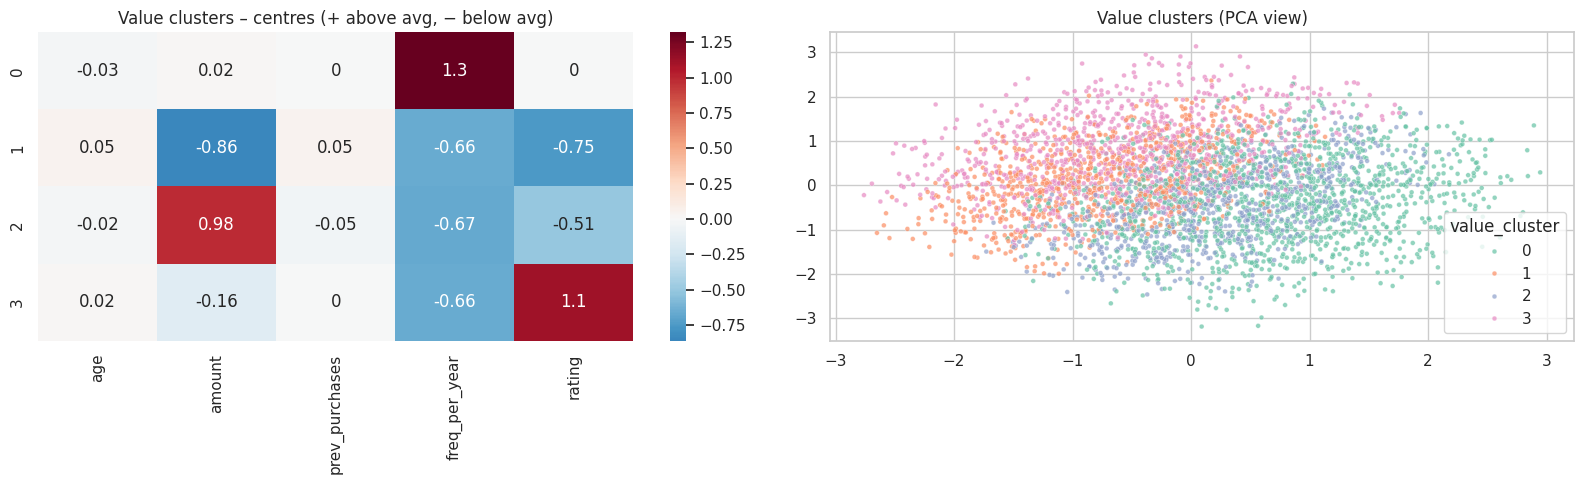

Value cluster 0: Middle-aged · Mid-spend · Frequent  (1305 customers, 34% of revenue) | age 41, $259/order, 52 buys/yr, 7 prev, rating 3.0
Value cluster 1: Middle-aged · Low-spend · Occasional  (818 customers, 11% of revenue) | age 42, $134/order, 19 buys/yr, 7 prev, rating 2.0
Value cluster 2: Middle-aged · High-spend · Occasional  (838 customers, 33% of revenue) | age 41, $395/order, 19 buys/yr, 7 prev, rating 2.3
Value cluster 3: Middle-aged · Mid-spend · Occasional  (939 customers, 22% of revenue) | age 41, $233/order, 19 buys/yr, 7 prev, rating 4.6


cluster,0,1,2,3,All
value_cluster,,,,,
0,348,306,348,303,1305
1,233,183,189,213,818
2,211,214,199,214,838
3,260,240,215,224,939
All,1052,943,951,954,3900


In [11]:
val_features = ["age", "amount", "prev_purchases", "freq_per_year", "rating"]
Xv = StandardScaler().fit_transform(df[val_features])

sil_v = {k: silhouette_score(Xv, KMeans(k, n_init=10, random_state=42).fit_predict(Xv),
                             sample_size=2000, random_state=42) for k in range(3, 7)}
print("Silhouette by k:", {k: round(v, 3) for k, v in sil_v.items()})

KV = 4          # change if another k in 3-5 scores clearly higher
kmv = KMeans(n_clusters=KV, n_init=20, random_state=42).fit(Xv)
df["value_cluster"] = kmv.labels_

vprof = df.groupby("value_cluster").agg(
    customers=("amount", "size"), avg_age=("age", "mean"), avg_amount=("amount", "mean"),
    purchases_per_year=("freq_per_year", "mean"), avg_prev_purchases=("prev_purchases", "mean"),
    avg_rating=("rating", "mean"), subscriber_pct=("sub_flag", "mean"),
    discount_pct=("disc_flag", "mean"), promo_pct=("promo_flag", "mean"))
for c in ["category", "item", "payment", "season", "location"]:
    vprof["top_" + c] = df.groupby("value_cluster")[c].agg(lambda s: s.value_counts().index[0])
vprof["revenue_share"] = df.groupby("value_cluster")["amount"].sum() / df["amount"].sum()
display(vprof.round(2).T)

# which features separate these clusters
centres_v = pd.DataFrame(kmv.cluster_centers_, columns=val_features)
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(centres_v.round(2), annot=True, cmap="RdBu_r", center=0, ax=ax[0]).set_title(
    "Value clusters – centres (+ above avg, − below avg)")
pv = PCA(2, random_state=42).fit_transform(Xv)
sns.scatterplot(x=pv[:, 0], y=pv[:, 1], hue=df["value_cluster"], palette="Set2", s=12, alpha=.7, ax=ax[1])
ax[1].set_title("Value clusters (PCA view)")
plt.tight_layout(); plt.show()

# automatic names
def vname(r):
    t = ["Young" if r.avg_age < 35 else "Senior" if r.avg_age > 50 else "Middle-aged"]
    t.append("High-spend" if r.avg_amount > 300 else "Low-spend" if r.avg_amount < 200 else "Mid-spend")
    t.append("Frequent" if r.purchases_per_year > 35 else "Occasional" if r.purchases_per_year < 22 else "Regular")
    if r.avg_prev_purchases > 9: t.append("Loyal")
    elif r.avg_prev_purchases < 5: t.append("New")
    return " · ".join(t)
vprof["segment"] = vprof.apply(vname, axis=1)
for cl, r in vprof.iterrows():
    print(f"Value cluster {cl}: {r.segment}  ({int(r.customers)} customers, {r.revenue_share:.0%} of revenue) "
          f"| age {r.avg_age:.0f}, ${r.avg_amount:.0f}/order, {r.purchases_per_year:.0f} buys/yr, "
          f"{r.avg_prev_purchases:.0f} prev, rating {r.avg_rating:.1f}")

# how the two segmentations overlap
display(pd.crosstab(df["value_cluster"], df["cluster"], margins=True))

**Finding:** frequency, order value and rating drive value → Frequent Regulars (34% revenue), Big Spenders at Risk (33%, rating 2.3), Happy Occasionals (22%), Unhappy Bargain Buyers (11%).

## 8. Export results

In [14]:
import os
os.makedirs("outputs", exist_ok=True)
for name in ["cat", "score", "age_card", "season_tbl", "loc_tbl", "tests", "profile"]:
    if name in globals():
        globals()[name].round(3).to_csv(f"outputs/{name}.csv")
df.to_csv("outputs/customers_with_clusters.csv", index=False)
print(os.listdir("outputs"))
!zip -qr outputs.zip outputs
from google.colab import files
files.download("outputs.zip")

['age_card.csv', 'customers_with_clusters.csv', 'tests.csv', 'season_tbl.csv', 'loc_tbl.csv', 'profile.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>